# Statistical model - Group means

Use group distribution paramaters to estimate new values

In [121]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.special import logit, expit
from scipy.stats import norm
from sklearn.model_selection import GroupShuffleSplit
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin



In [122]:
train_df_all = pd.read_csv("train_augmented.csv",index_col=0)
train_df_all.columns

Index(['category_name', 'geography_name', 'wave_date', 'question_text',
       'qualifying_options', 'disqualifying_options', 'weight_3',
       'base_weight_3', 'percentage_3', 'timeframe_months', 'have_you_quest',
       'are_you_quest', 'multi_choice_quest', 'do_you_own_quest',
       'n_qualifying', 'n_disqualifying', 'qualifying_has_no',
       'qualifying_has_yes', 'continent', 'product_category', 'broad_category',
       'is_luxury', 'is_subscription', 'audience_breadth',
       'purchase_frequency', 'usage_frequency', 'cost_tier'],
      dtype='str')

In [123]:
train_df_all["logit_incidence"] = logit( train_df_all["percentage_3"] )
train_df_all["logit_incidence"].describe()

count    829.000000
mean       0.298250
std        0.995341
min       -3.009467
25%       -0.447312
50%        0.159980
75%        0.942979
max        6.868457
Name: logit_incidence, dtype: float64

<Axes: xlabel='audience_breadth', ylabel='percentage_3'>

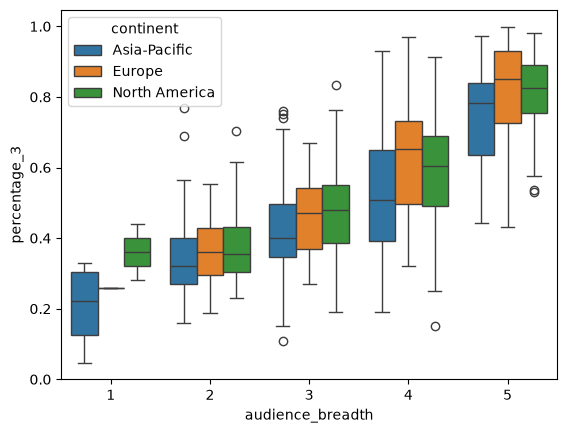

In [124]:
sns.boxplot(data=train_df_all, x="audience_breadth", y="percentage_3", hue="continent")

In [125]:
train_df_all.logit_incidence.describe()

count    829.000000
mean       0.298250
std        0.995341
min       -3.009467
25%       -0.447312
50%        0.159980
75%        0.942979
max        6.868457
Name: logit_incidence, dtype: float64

## Split dataset into train and validation sets

We want the validation split to have completely new product categories, as will be the case for the test set

In [126]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, val_idx = next(splitter.split(
    train_df_all,
    groups=train_df_all["product_category"]
))

train = train_df_all.iloc[train_idx].copy()
val = train_df_all.iloc[val_idx].copy()

print(f"Train dataset: {len(train)} rows")
print(f"Validation dataset: {len(val)} rows")

Train dataset: 653 rows
Validation dataset: 176 rows


In [127]:
target_col = "logit_incidence"

In [128]:
params = train.groupby(["audience_breadth", "continent"])[target_col].apply(lambda x: pd.Series({
    "mean":x.mean(),
    "std":x.std(),
    "stderr":x.std()/np.sqrt(len(x)),
})).unstack()

params_worldwide = train.groupby(["audience_breadth"])[target_col].apply(lambda x: pd.Series({
    "mean":x.mean(),
    "std":x.std(),
    "stderr":x.std()/np.sqrt(len(x)),
})).unstack()

params_worldwide

,mean,std,stderr
audience_breadth,,,
1,-1.308288,0.959608,0.391759
2,-0.673102,0.489970,0.069996
3,-0.251104,0.531921,0.040441
4,0.139869,0.731493,0.045989
5,1.386757,0.898831,0.068535


In [129]:
params["pred_err"] = (params["std"]**2 + params["stderr"]**2)**.5
params_worldwide["pred_err"] = (params_worldwide["std"]**2 + params_worldwide["stderr"]**2)**.5
params

mean       std    stderr  pred_err
audience_breadth continent                                            
1                Asia-Pacific  -1.872711  1.074379  0.620293  1.240586
                 Europe        -1.045969       NaN       NaN       NaN
                 North America -0.592812  0.497308  0.351650  0.609075
2                Asia-Pacific  -0.774277  0.465980  0.095118  0.475589
                 Europe        -0.616297  0.522707  0.184805  0.554414
                 North America -0.556999  0.507200  0.123014  0.521905
3                Asia-Pacific  -0.332381  0.518844  0.051373  0.521381
                 Europe        -0.206233  0.415833  0.100854  0.427889
                 North America -0.111706  0.565562  0.076963  0.570774
4                Asia-Pacific   0.039574  0.679887  0.050817  0.681784
                 Europe         0.495790  1.022904  0.228728  1.048165
                 North America  0.340505  0.702725  0.095629  0.709202
5                Asia-Pacific   1.189531  0.705800  0.068553  0.709121
                 Europe         1.862044  1.504425  0.328292  1.539828
                 North America  1.629532  0.812673  0.121146  0.821653

In [130]:
nulls = params.loc[params.pred_err.isnull()].index.get_level_values("audience_breadth")
params.loc[params.pred_err.isnull()] = params_worldwide.loc[nulls].values
params

mean       std    stderr  pred_err
audience_breadth continent                                            
1                Asia-Pacific  -1.872711  1.074379  0.620293  1.240586
                 Europe        -1.308288  0.959608  0.391759  1.036496
                 North America -0.592812  0.497308  0.351650  0.609075
2                Asia-Pacific  -0.774277  0.465980  0.095118  0.475589
                 Europe        -0.616297  0.522707  0.184805  0.554414
                 North America -0.556999  0.507200  0.123014  0.521905
3                Asia-Pacific  -0.332381  0.518844  0.051373  0.521381
                 Europe        -0.206233  0.415833  0.100854  0.427889
                 North America -0.111706  0.565562  0.076963  0.570774
4                Asia-Pacific   0.039574  0.679887  0.050817  0.681784
                 Europe         0.495790  1.022904  0.228728  1.048165
                 North America  0.340505  0.702725  0.095629  0.709202
5                Asia-Pacific   1.189531  0.705800  0.068553  0.709121
                 Europe         1.862044  1.504425  0.328292  1.539828
                 North America  1.629532  0.812673  0.121146  0.821653

In [131]:
margin_mult = norm.ppf(0.90) 
margin_mult

np.float64(1.2815515655446004)

In [146]:
def apply_to_dataset(params, df):
    df = df.merge(params.reset_index())
    df = df.rename(columns={"mean":"point_estimate"})
    df["lower_80"] = df["point_estimate"] - margin_mult * df["pred_err"]
    df["upper_80"] = df["point_estimate"] + margin_mult * df["pred_err"]
    return df

def add_residuals(df, target_col):
    df["residual"] = df[target_col] - df["point_estimate"]
    df["in_interval"] = ((df[target_col] > df["lower_80"]) &
                             (df[target_col] < df["upper_80"]))
    return df

def expit_convert(df):
    df = df.rename(columns={
        "point_estimate":"logit_estimate",
        "lower_80":"logit_lower_80",
        "upper_80":"logit_upper_80",
    })
    df["lower_80"] = expit(df["logit_lower_80"])
    df["upper_80"] = expit(df["logit_upper_80"])
    df["point_estimate"] = expit(df["logit_estimate"])
    return df

In [147]:
val_params = apply_to_dataset(params, val)
val_params = add_residuals(val_params, target_col)

## Check that actual data is within coverage interval

In [148]:
coverage = val_params["in_interval"].mean()
print("80% interval coverage:", coverage)



80% interval coverage: 0.7727272727272727


In [149]:
mae = val_params["residual"].abs().mean()
print("Mean Absolute Error:", mae)


Mean Absolute Error: 0.5758341999573885


# Apply to test dataset

In [150]:
test = pd.read_csv("test_augmented.csv")
test.columns

Index(['Unnamed: 0', 'prediction_id', 'category_name', 'geography_name',
       'wave_date', 'question_text', 'qualifying_options',
       'disqualifying_options', 'timeframe_months', 'have_you_quest',
       'are_you_quest', 'multi_choice_quest', 'do_you_own_quest',
       'n_qualifying', 'n_disqualifying', 'qualifying_has_no',
       'qualifying_has_yes', 'continent', 'product_category', 'broad_category',
       'is_luxury', 'is_subscription', 'audience_breadth',
       'purchase_frequency', 'usage_frequency', 'cost_tier'],
      dtype='str')

In [153]:
train_df_all["logit_incidence"] = logit( train_df_all["percentage_3"] )

test_results = apply_to_dataset(params, test)
test_results = expit_convert(test_results)

In [154]:
test_results["prediction_id point_estimate lower_80 upper_80".split()].to_csv("predictions_baseline.csv")